In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"

print("Project folder:", PROJECT_ROOT)
print("Training file exists:", train_path.exists())
print("Testing file exists:", test_path.exists())

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Project folder: c:\Users\adars\TraceGraph-AI
Training file exists: True
Testing file exists: True
Training shape: (4786, 58)
Testing shape: (1220, 58)


In [2]:
print("COLUMNS IN TRAINING DATA")
print(train_df.columns.tolist())

print("\nFIRST FIVE ROWS")
display(train_df.head())

print("\nDATA TYPES")
display(train_df.dtypes.to_frame("Data Type"))

COLUMNS IN TRAINING DATA
['timestamp', 'src_ip', 'dst_ip', 'source', 'proto', 'dst_port', 'attack_instance_id', 'session_id', 'flow_id', 'request_id', 'attack_family', 'attack_stage', 'method', 'status_code', 'response_bytes', 'has_ua', 'f_has_sqli', 'f_has_xss', 'f_has_lfi', 'f_has_cmd', 'f_has_ssrf', 'f_has_traversal', 'f_is_scanner_ua', 'f_query_len', 'f_path_depth', 'f_has_encoded', 'f_has_sql_comment', 'f_req_count_1s', 'f_req_rate_1s', 'f_req_count_10s', 'f_req_rate_10s', 'f_req_count_60s', 'f_req_rate_60s', 'f_error_ratio_10s', 'f_unique_paths_10s', 'f_404_count_10s', 'f_404_count_60s', 'f_suricata_alerts_60s', 'f_suricata_high_sev_60s', 'f_suricata_unique_sigs', 'f_flow_pkts_out_60s', 'f_flow_pkts_in_60s', 'f_flow_bytes_out_60s', 'f_flow_syn_ratio', 'f_flow_count_60s', 'f_flow_duration', 'f_flow_pkts_total', 'f_flow_bytes_total', 'f_tcp_syn', 'f_tcp_ack', 'f_tcp_fin', 'f_tcp_rst', 'f_session_req_count', 'f_session_duration', 'f_session_unique_paths', 'f_session_error_count', 'f

,timestamp,src_ip,dst_ip,source,proto,dst_port,attack_instance_id,session_id,flow_id,request_id,...,f_tcp_syn,f_tcp_ack,f_tcp_fin,f_tcp_rst,f_session_req_count,f_session_duration,f_session_unique_paths,f_session_error_count,f_session_req_rate,label
0,1.790478e+09,192.168.70.132,192.168.70.50,nginx,http,200,ATT_192.168.70.132_14920649,S_192.168.70.132_59682599,NaN,REQ_0148583,...,0,0,0,0,3136,28.995,3126,3123,108.155,XSS_EVASION
1,1.790479e+09,192.168.70.132,192.168.70.50,nginx,http,404,ATT_192.168.70.132_14920660,S_192.168.70.132_59682643,NaN,REQ_0173410,...,0,0,0,0,4760,17.000,4616,4615,280.000,PATH_TRAVERSAL
2,1.790473e+09,192.168.70.132,192.168.70.50,nginx,http,301,ATT_192.168.70.132_14920610,S_192.168.70.132_59682441,NaN,REQ_0059429,...,0,0,0,0,37,26.000,6,4,1.423,WEB_FINGERPRINT
3,1.790480e+09,192.168.70.132,192.168.70.50,nginx,http,404,ATT_192.168.70.132_14920663,S_192.168.70.132_59682652,NaN,REQ_0178392,...,0,0,0,0,4825,22.000,4616,4615,219.318,SQLMAP_EVASION
4,1.790470e+09,192.168.70.132,192.168.70.50,nginx,http,301,ATT_192.168.70.132_14920584,S_192.168.70.132_59682339,NaN,REQ_0004856,...,0,0,0,0,1221,29.369,880,874,41.575,UA_SPOOF



DATA TYPES


,Data Type
timestamp,float64
src_ip,str
dst_ip,str
source,str
proto,str
dst_port,int64
attack_instance_id,str
session_id,str
flow_id,str
request_id,str


In [3]:
print("MISSING VALUES")
missing = train_df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))

print("\nDUPLICATE ROWS")
print("Training:", train_df.duplicated().sum())
print("Testing:", test_df.duplicated().sum())

print("\nTRAIN/TEST COLUMN MATCH")
print(set(train_df.columns) == set(test_df.columns))

MISSING VALUES


flow_id         3580
request_id      1206
method          1206
attack_stage     214
dtype: int64


DUPLICATE ROWS
Training: 0
Testing: 0

TRAIN/TEST COLUMN MATCH
True


In [4]:
if "label" in train_df.columns:
    print("Training label distribution:")
    display(train_df["label"].value_counts(dropna=False).to_frame("Count"))

    print("\nLabel proportions:")
    display(
        train_df["label"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
        .to_frame("Percentage")
    )
else:
    print("No column named 'label' found. We need to identify the target.")

Training label distribution:


,Count
label,
ICMP_PING,300
WEB_BRUTEFORCE,291
UA_ROTATION,241
LFI_EVASION,236
SQLI_ATTEMPT,235
XSS_ATTEMPT,233
CMD_INJECTION,233
LFI_ATTEMPT,232
PATH_TRAVERSAL,231



Label proportions:


,Percentage
label,
ICMP_PING,6.27
WEB_BRUTEFORCE,6.08
UA_ROTATION,5.04
LFI_EVASION,4.93
SQLI_ATTEMPT,4.91
XSS_ATTEMPT,4.87
CMD_INJECTION,4.87
LFI_ATTEMPT,4.85
PATH_TRAVERSAL,4.83


In [5]:
possible_leakage_columns = [
    "label",
    "attack_family",
    "attack_stage",
    "attack_instance_id",
    "session_id",
    "flow_id",
    "request_id",
]

print("Potentially sensitive columns present:")
print([c for c in possible_leakage_columns if c in train_df.columns])

print("\nPotential identifier uniqueness:")
for col in ["attack_instance_id", "session_id", "flow_id", "request_id"]:
    if col in train_df.columns:
        print(
            f"{col}: {train_df[col].nunique(dropna=False)} unique values "
            f"out of {len(train_df)} rows"
        )

Potentially sensitive columns present:
['label', 'attack_family', 'attack_stage', 'attack_instance_id', 'session_id', 'flow_id', 'request_id']

Potential identifier uniqueness:
attack_instance_id: 87 unique values out of 4786 rows
session_id: 202 unique values out of 4786 rows
flow_id: 1207 unique values out of 4786 rows
request_id: 3581 unique values out of 4786 rows


In [6]:
# 1. Number of classes and full label distribution
print("Number of training classes:", train_df["label"].nunique())
print("\nComplete label distribution:")
display(train_df["label"].value_counts().to_frame("Count"))

# 2. Missing-value percentages
print("\nMissing-value percentages:")
display(
    (train_df.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .head(15)
    .to_frame("Missing %")
)

# 3. Identifier uniqueness and examples
for col in ["attack_instance_id", "session_id", "flow_id", "request_id"]:
    if col in train_df.columns:
        print(f"\n{col}")
        print("Unique non-missing values:", train_df[col].nunique())
        print("Missing values:", train_df[col].isnull().sum())
        print("Examples:", train_df[col].dropna().astype(str).head(3).tolist())

# 4. Check whether target labels are missing
print("\nMissing target labels:", train_df["label"].isnull().sum())

Number of training classes: 32

Complete label distribution:


,Count
label,
ICMP_PING,300
WEB_BRUTEFORCE,291
UA_ROTATION,241
LFI_EVASION,236
SQLI_ATTEMPT,235
XSS_ATTEMPT,233
CMD_INJECTION,233
LFI_ATTEMPT,232
PATH_TRAVERSAL,231



Missing-value percentages:


,Missing %
flow_id,74.80
request_id,25.20
method,25.20
attack_stage,4.47
src_ip,0.00
timestamp,0.00
dst_port,0.00
proto,0.00
dst_ip,0.00
source,0.00



attack_instance_id
Unique non-missing values: 87
Missing values: 0
Examples: ['ATT_192.168.70.132_14920649', 'ATT_192.168.70.132_14920660', 'ATT_192.168.70.132_14920610']

session_id
Unique non-missing values: 202
Missing values: 0
Examples: ['S_192.168.70.132_59682599', 'S_192.168.70.132_59682643', 'S_192.168.70.132_59682441']

flow_id
Unique non-missing values: 1206
Missing values: 3580
Examples: ['FLOW_0001329', 'FLOW_0000377', 'FLOW_0000873']

request_id
Unique non-missing values: 3580
Missing values: 1206
Examples: ['REQ_0148583', 'REQ_0173410', 'REQ_0059429']

Missing target labels: 0


In [7]:
# A. Number and distribution of all target classes
print("Number of classes:", train_df["label"].nunique())
display(train_df["label"].value_counts().to_frame("Count"))

# B. Understand the record types
print("\nRecord counts by source:")
display(train_df["source"].value_counts(dropna=False).to_frame("Count"))

print("\nMissing identifier combinations:")
display(
    pd.crosstab(
        train_df["flow_id"].isna(),
        train_df["request_id"].isna(),
        rownames=["flow_id missing"],
        colnames=["request_id missing"]
    )
)

# C. Investigate potential target leakage
for col in ["attack_family", "attack_stage"]:
    if col in train_df.columns:
        print(f"\nTarget label versus {col}:")
        display(pd.crosstab(train_df["label"], train_df[col], dropna=False))

# D. Check whether train and test share attack instances
train_attacks = set(train_df["attack_instance_id"].dropna())
test_attacks = set(test_df["attack_instance_id"].dropna())

print("\nShared attack instances between train and test:",
      len(train_attacks & test_attacks))

Number of classes: 32


,Count
label,
ICMP_PING,300
WEB_BRUTEFORCE,291
UA_ROTATION,241
LFI_EVASION,236
SQLI_ATTEMPT,235
XSS_ATTEMPT,233
CMD_INJECTION,233
LFI_ATTEMPT,232
PATH_TRAVERSAL,231



Record counts by source:


,Count
source,
nginx,3580
suricata,1206



Missing identifier combinations:


...


Target label versus attack_family:


attack_family,Benign,Credential-Access,Defense-Evasion,Denial-of-Service,Reconnaissance,Web-Exploitation
label,,,,,,
CMD_INJECTION,0,0,0,0,0,233
CREDENTIAL_STUFFING,0,31,0,0,0,0
DIR_ENUM,0,0,0,0,32,0
DIR_FUZZ,0,0,0,0,31,0
HEADER_INJECTION,0,0,0,0,0,154
HPP_ATTACK,0,0,0,0,0,93
HTTP_SMUGGLING,0,0,0,0,0,31
ICMP_FLOOD,0,0,0,131,0,0
ICMP_PING,0,0,0,0,300,0



Target label versus attack_stage:


attack_stage,Credential-Access,Defense-Evasion,Discovery,Impact,Initial-Access/Execution,NaN
label,,,,,,
CMD_INJECTION,0,0,0,0,233,0
CREDENTIAL_STUFFING,31,0,0,0,0,0
DIR_ENUM,0,0,32,0,0,0
DIR_FUZZ,0,0,31,0,0,0
HEADER_INJECTION,0,0,0,0,154,0
HPP_ATTACK,0,0,0,0,93,0
HTTP_SMUGGLING,0,0,0,0,31,0
ICMP_FLOOD,0,0,0,131,0,0
ICMP_PING,0,0,300,0,0,0



Shared attack instances between train and test: 38


In [8]:
excluded_columns = [
    "label",
    "attack_family",
    "attack_stage",
    "attack_instance_id",
    "session_id",
    "flow_id",
    "request_id",
]

candidate_features = [
    col for col in train_df.columns
    if col not in excluded_columns
]

print("Number of candidate features:", len(candidate_features))
print("\nCandidate feature names:")
for col in candidate_features:
    print(col)

Number of candidate features: 51

Candidate feature names:
timestamp
src_ip
dst_ip
source
proto
dst_port
method
status_code
response_bytes
has_ua
f_has_sqli
f_has_xss
f_has_lfi
f_has_cmd
f_has_ssrf
f_has_traversal
f_is_scanner_ua
f_query_len
f_path_depth
f_has_encoded
f_has_sql_comment
f_req_count_1s
f_req_rate_1s
f_req_count_10s
f_req_rate_10s
f_req_count_60s
f_req_rate_60s
f_error_ratio_10s
f_unique_paths_10s
f_404_count_10s
f_404_count_60s
f_suricata_alerts_60s
f_suricata_high_sev_60s
f_suricata_unique_sigs
f_flow_pkts_out_60s
f_flow_pkts_in_60s
f_flow_bytes_out_60s
f_flow_syn_ratio
f_flow_count_60s
f_flow_duration
f_flow_pkts_total
f_flow_bytes_total
f_tcp_syn
f_tcp_ack
f_tcp_fin
f_tcp_rst
f_session_req_count
f_session_duration
f_session_unique_paths
f_session_error_count
f_session_req_rate


In [9]:
# Columns that should not be used as initial predictive features
excluded_columns = [
    "label",
    "attack_family",
    "attack_stage",
    "attack_instance_id",
    "session_id",
    "flow_id",
    "request_id",
    "timestamp",
    "src_ip",
    "dst_ip",
]

# Explicit signature and alert features are excluded
# from the first conservative baseline.
signature_columns = [
    "f_has_sqli",
    "f_has_xss",
    "f_has_lfi",
    "f_has_cmd",
    "f_has_ssrf",
    "f_has_traversal",
    "f_is_scanner_ua",
    "f_has_sql_comment",
    "f_suricata_alerts_60s",
    "f_suricata_high_sev_60s",
    "f_suricata_unique_sigs",
]

excluded_columns += signature_columns

feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

X_train = train_df[feature_columns].copy()
y_train = train_df["label"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["label"].copy()

print("Number of selected features:", len(feature_columns))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nSelected features:")
print(feature_columns)

Number of selected features: 37
Training records: 4786
Testing records: 1220

Selected features:
['source', 'proto', 'dst_port', 'method', 'status_code', 'response_bytes', 'has_ua', 'f_query_len', 'f_path_depth', 'f_has_encoded', 'f_req_count_1s', 'f_req_rate_1s', 'f_req_count_10s', 'f_req_rate_10s', 'f_req_count_60s', 'f_req_rate_60s', 'f_error_ratio_10s', 'f_unique_paths_10s', 'f_404_count_10s', 'f_404_count_60s', 'f_flow_pkts_out_60s', 'f_flow_pkts_in_60s', 'f_flow_bytes_out_60s', 'f_flow_syn_ratio', 'f_flow_count_60s', 'f_flow_duration', 'f_flow_pkts_total', 'f_flow_bytes_total', 'f_tcp_syn', 'f_tcp_ack', 'f_tcp_fin', 'f_tcp_rst', 'f_session_req_count', 'f_session_duration', 'f_session_unique_paths', 'f_session_error_count', 'f_session_req_rate']


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical features:", categorical_features)
print("Numerical feature count:", len(numerical_features))

# Preprocessing for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build model pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
baseline_model.fit(X_train, y_train)

print("Baseline model training complete!")

C:\Users\adars\AppData\Local\Temp\ipykernel_42796\3221494393.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Categorical features: ['source', 'proto', 'method']
Numerical feature count: 34
Baseline model training complete!


In [13]:
y_pred = baseline_model.predict(X_test)

print("Baseline accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))



Baseline accuracy: 0.9328

Classification report:
                     precision    recall  f1-score   support

      CMD_INJECTION       0.97      0.97      0.97        67
CREDENTIAL_STUFFING       0.83      0.56      0.67         9
           DIR_ENUM       0.67      1.00      0.80         8
           DIR_FUZZ       0.62      0.56      0.59         9
   HEADER_INJECTION       0.98      0.91      0.94        46
         HPP_ATTACK       0.82      0.85      0.84        27
     HTTP_SMUGGLING       0.56      0.56      0.56         9
         ICMP_FLOOD       1.00      1.00      1.00        29
        LFI_ATTEMPT       0.94      0.97      0.96        68
        LFI_EVASION       0.97      0.92      0.94        64
             NORMAL       1.00      1.00      1.00        86
     PATH_TRAVERSAL       0.97      0.97      0.97        69
      REFLECTED_XSS       0.98      0.91      0.94        45
          SLOWLORIS       0.73      0.89      0.80         9
    SLOW_BRUTEFORCE       0.45    

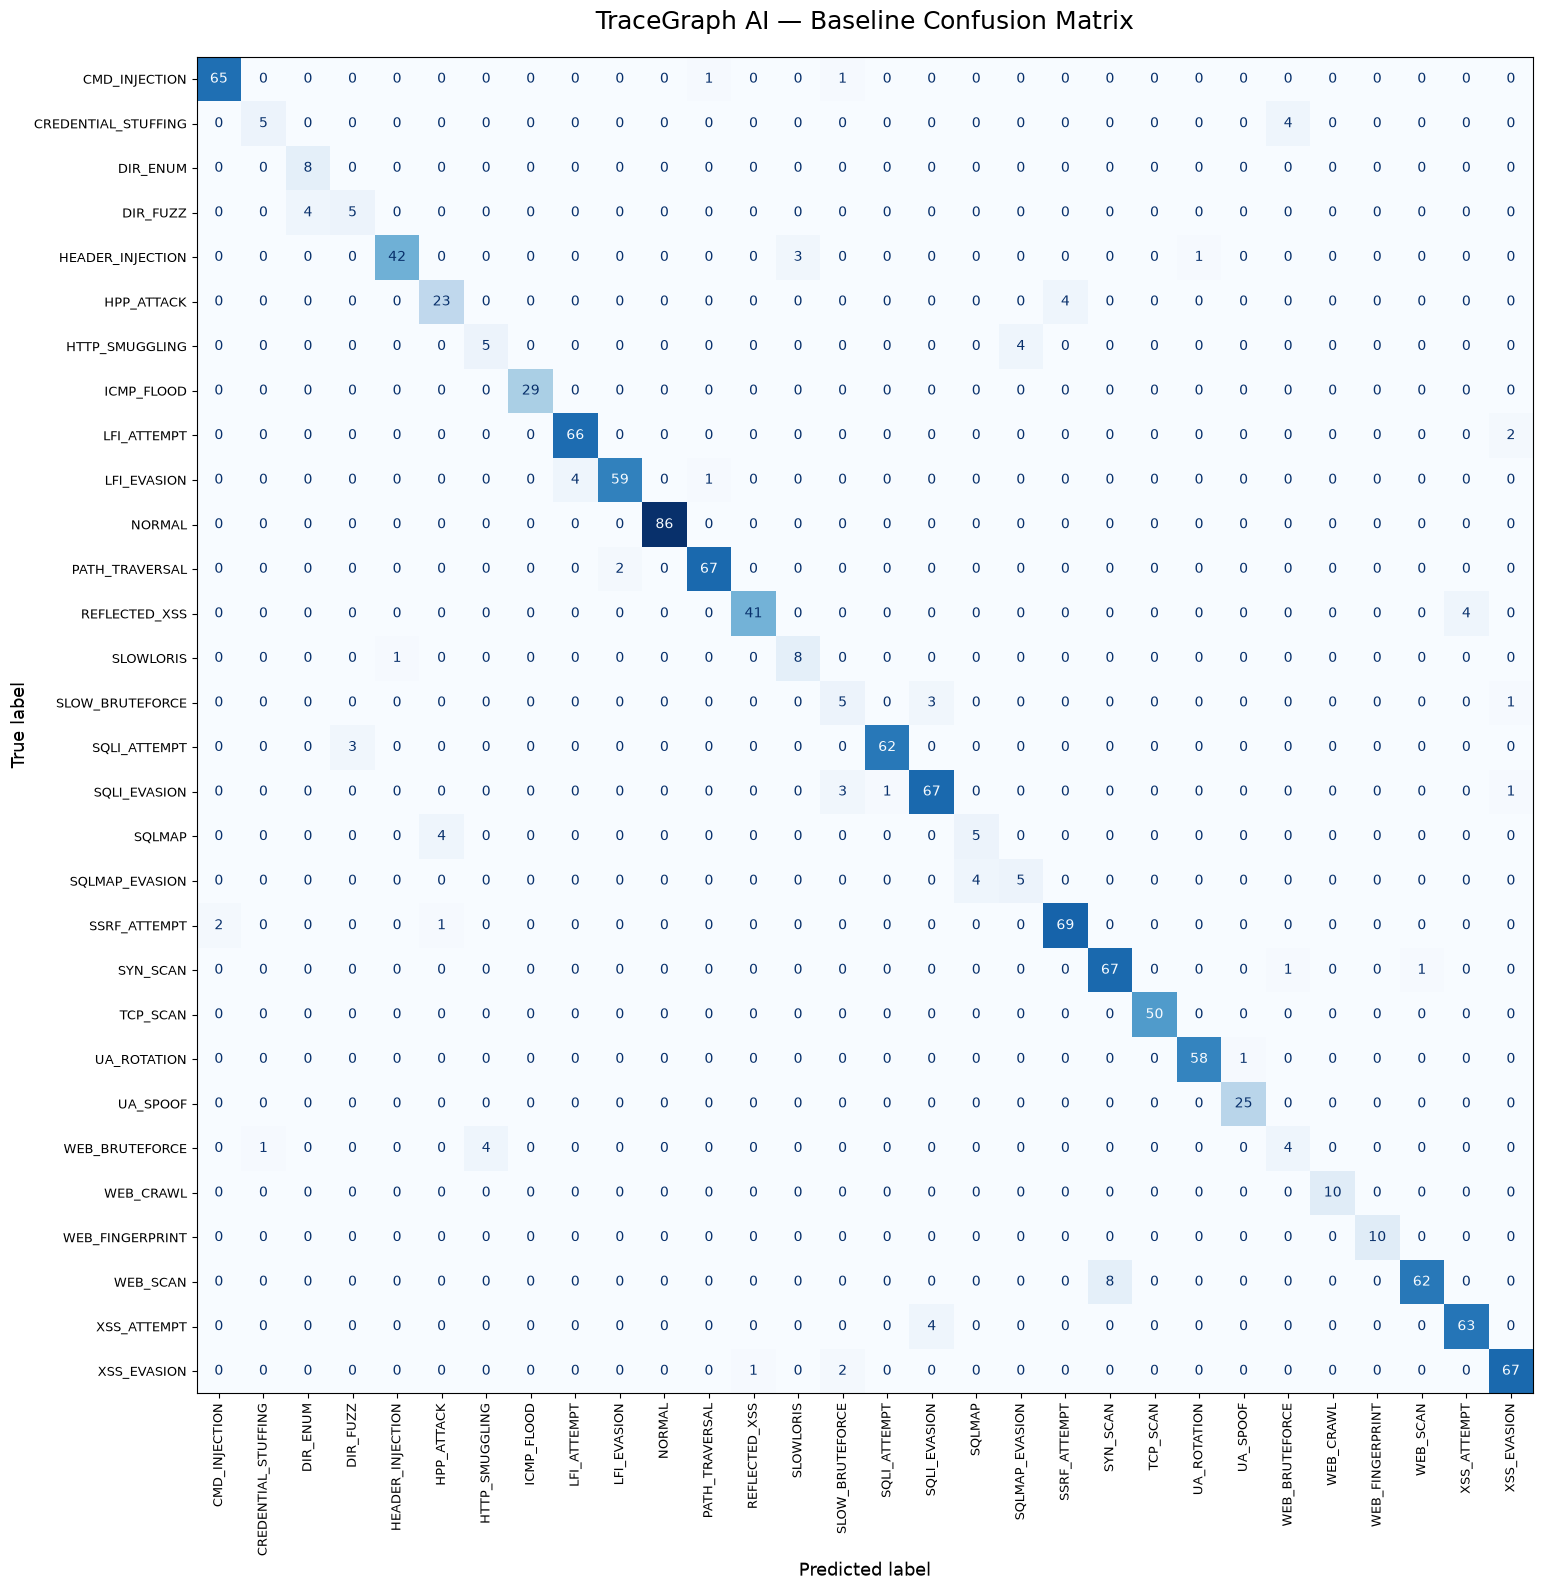

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 16))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax
)

ax.set_title("TraceGraph AI — Baseline Confusion Matrix", fontsize=18, pad=20)
ax.set_xlabel("Predicted label", fontsize=13)
ax.set_ylabel("True label", fontsize=13)
ax.tick_params(axis="both", labelsize=9)

plt.tight_layout()
plt.show()